# Partial rank correlations: SatGen vs. BolshoiP vs. VSMDPL

**Question.** Figure 4 of the paper shows that SatGen's assembly-bias signals are weaker than the simulations'. Is the deficit carried by the host's formation time ($z_{50}$), by its concentration ($c_{\rm vir}$), or by both?

**Approach.** In every host-mass bin we measure the rank correlation between subhalo abundance and *one* secondary property while holding the *other* fixed (a partial rank correlation). Everything else (samples, mass bins, variables, jackknife) is identical to Figure 4, which is made by `jsm_simload.NormalizeData` in `notebooks/correlations/rho_mat_comp.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.style.use('../../../SatGen/notebooks/paper1/paper.mplstyle')
double_textwidth = 7.0  # inches
single_textwidth = 3.5  # inches

## 1. Data

| Model | File | Notes |
|---|---|---|
| SatGen | `data/zhao/DF_test/DF_1/artificial_all.csv` | fiducial DF ($\beta_{\rm DF}=0.75$), "artificial" subhalo regime, $c_{\rm vir}$ from Zhao et al. (2009); 1000 trees at each of 8 exact masses |
| BolshoiP | `data/summary_tabs/BolshoiP/BolshoiP_all_500.csv` | all distinct hosts (`upid == -1`), $m_{\rm thresh}=7.75\times10^{10}\,h^{-1}M_\odot$ (500 particles), $c_{\rm vir}$ from $V_{\max}/V_{\rm vir}$ (`ch_K`) |
| VSMDPL | `data/summary_tabs/VSMDPL/vsmdpl_all_500.csv` | same definitions; the same $m_{\rm thresh}$ is $\approx 12{,}500$ particles |

In all three, subhalos are counted only if $m_{\rm sub} \ge m_{\rm thresh}$ and $|\vec r| \le R_{\rm vir}$. The columns used are `Nsub`, `fsub`, `log1pz50` and `logc`. Hosts with $N_{\rm sub}=0$ are kept (they are tied at the lowest rank), exactly as in Figure 4.

In [2]:
files = {
    "SatGen":   "../../data/zhao/DF_test/DF_1/artificial_all.csv",
    "BolshoiP": "../../data/summary_tabs/BolshoiP/BolshoiP_all_500.csv",
    "VSMDPL":   "../../data/summary_tabs/VSMDPL/vsmdpl_all_500.csv",
}
data = {name: pd.read_csv(path) for name, path in files.items()}

style = {
    "SatGen":   dict(color="C0",            marker=".", label="SatGen"),
    "BolshoiP": dict(color="purple",        marker="*", label="BolshoiP"),
    "VSMDPL":   dict(color="palevioletred", marker="*", label="VSMDPL"),
}

## 2. Mass bins

Identical to `NormalizeData.grab_subsample`: eight bins centred on $\log M_{\rm vir} \in \{12.6, 12.8, \dots, 14.0\}$, each covering

$$\mathbb{S}_m = \left\{\, \text{hosts with } m - 0.1 < \log M_{\rm vir} \le m + 0.1 \,\right\}.$$

In [3]:
bin_centers = np.linspace(12.6, 14.0, 8)
half_width = 0.1

def mass_bin(df, center):
    return df[(df["logMvir"] > center - half_width) & (df["logMvir"] <= center + half_width)]

pd.DataFrame({name: [len(mass_bin(df, m)) for m in bin_centers] for name, df in data.items()},
             index=[f"{m:.1f}" for m in bin_centers]).T.rename_axis("N_host")

,12.6,12.8,13.0,13.2,13.4,13.6,13.8,14.0
N_host,,,,,,,,
SatGen,1000,1000,1000,1000,1000,1000,1000,1000
BolshoiP,8135,5359,3413,2168,1368,850,501,309
VSMDPL,1651,1127,719,463,282,177,116,71


## 3. The measurement

Within one mass bin, let $X$ be the subhalo abundance ($N_{\rm sub}$ or $f_{\rm sub}$), $Z = \log(1+z_{50})$ and $C = \log c_{\rm vir}$. Replace each variable by its rank within the bin (ties get their average rank), $R_X$, $R_Z$, $R_C$. The Spearman coefficient is the Pearson coefficient of the ranks,

$$\rho_S(X|Z) \equiv \mathrm{corr}(R_X, R_Z),$$

so $\rho_S(N_{\rm sub}|z_{50})$, $\rho_S(N_{\rm sub}|c_{\rm vir})$, etc. are exactly the quantities in Figure 4.

**Notation for partial correlations.** $\rho_S(X, Y \,|\, W)$ is the rank correlation between $X$ and $W$ once $Y$ is held fixed. As in the ordinary $\rho_S(X|W)$, the variable after the bar is the one correlated with $X$; the variable between the comma and the bar is the one held fixed.

The **concentration channel**, the correlation of $X$ and $C$ at fixed $Z$, is the correlation between the parts of $R_X$ and $R_C$ that a straight line in $R_Z$ cannot predict:

$$\rho_S(X, Z \,|\, C) \;=\; \frac{\rho_S(X|C) - \rho_S(X|Z)\,\rho_S(Z|C)}{\sqrt{\left[1-\rho_S(X|Z)^2\right]\left[1-\rho_S(Z|C)^2\right]}}\,.$$

The **formation-time channel**, the correlation of $X$ and $Z$ at fixed $C$, is the same expression with $Z \leftrightarrow C$:

$$\rho_S(X, C \,|\, Z) \;=\; \frac{\rho_S(X|Z) - \rho_S(X|C)\,\rho_S(Z|C)}{\sqrt{\left[1-\rho_S(X|C)^2\right]\left[1-\rho_S(Z|C)^2\right]}}\,.$$

**Reading it.** If $X$ were related to $c_{\rm vir}$ *only* through $z_{50}$, then $\rho_S(X|C) \simeq \rho_S(X|Z)\,\rho_S(Z|C)$ and $\rho_S(X, Z\,|\,C) \simeq 0$. A non-zero $\rho_S(X, Z\,|\,C)$ means $c_{\rm vir}$ carries information about $X$ that $z_{50}$ does not (and vice versa for $\rho_S(X, C\,|\,Z)$). It is not a statement about causation.

**Uncertainties.** Same jackknife as `jsm_stats.jackknife_correlation`: the hosts in a bin are randomly split into $N_{\rm jk}=10$ groups; removing group $i$ and recomputing gives $\rho_i$, and

$$\sigma^2_\rho = \frac{N_{\rm jk}-1}{N_{\rm jk}} \sum_{i=1}^{N_{\rm jk}} \left(\rho_i - \bar\rho\right)^2 .$$

The random split uses a fixed seed so the error bars are reproducible.

In [4]:
N_JACK = 10
SEED = 42

def rank_corrs(x, z, c):
    # the three pairwise Spearman coefficients and the two partials
    r_xz = stats.spearmanr(x, z)[0]
    r_xc = stats.spearmanr(x, c)[0]
    r_zc = stats.spearmanr(z, c)[0]
    # rho(X, z50 | c): X vs c at fixed z50 (concentration channel)
    c_channel = (r_xc - r_xz * r_zc) / np.sqrt((1 - r_xz**2) * (1 - r_zc**2))
    # rho(X, c | z50): X vs z50 at fixed c (formation-time channel)
    z_channel = (r_xz - r_xc * r_zc) / np.sqrt((1 - r_xc**2) * (1 - r_zc**2))
    return np.array([r_xz, r_xc, r_zc, c_channel, z_channel])

def jackknife(x, z, c, n_jack=N_JACK, seed=SEED):
    x, z, c = map(np.asarray, (x, z, c))
    full = rank_corrs(x, z, c)
    groups = np.array_split(np.random.default_rng(seed).permutation(len(x)), n_jack)
    reps = []
    for g in groups:
        keep = np.ones(len(x), bool)
        keep[g] = False
        reps.append(rank_corrs(x[keep], z[keep], c[keep]))
    reps = np.array(reps)
    err = np.sqrt((n_jack - 1) / n_jack * np.sum((reps - reps.mean(0))**2, axis=0))
    return full, err

columns = ["rho(X|z50)", "rho(X|c)", "rho(z50|c)", "rho(X,z50|c)", "rho(X,c|z50)"]

def measure(df, xkey):
    rows = []
    for m in bin_centers:
        s = mass_bin(df, m)
        val, err = jackknife(s[xkey], s["log1pz50"], s["logc"])
        rows.append([m, len(s), *val, *err])
    return pd.DataFrame(rows, columns=["logMvir", "N_host"] + columns + [k + "_err" for k in columns])

results = {(name, x): measure(df, x) for name, df in data.items() for x in ["Nsub", "fsub"]}

## 4. Results

Each table lists, per mass bin, $\rho_S(X|z_{50})$, $\rho_S(X|c_{\rm vir})$, $\rho_S(z_{50}|c_{\rm vir})$ and the two partial correlations, with jackknife errors. The first two columns should reproduce Figure 4.

In [5]:
def show(name, x):
    t = results[(name, x)]
    out = t[["logMvir", "N_host"]].copy()
    for k in columns:
        out[k] = [f"{v:+.2f} ± {e:.2f}" for v, e in zip(t[k], t[k + "_err"])]
    print(f"{name}   X = {x}")
    display(out.set_index("logMvir"))

for x in ["Nsub", "fsub"]:
    for name in data:
        show(name, x)

SatGen   X = Nsub


,N_host,rho(X|z50),rho(X|c),rho(z50|c),"rho(X,z50|c)","rho(X,c|z50)"
logMvir,,,,,,
12.6,1000,-0.31 ± 0.03,-0.19 ± 0.03,+0.40 ± 0.02,-0.08 ± 0.03,-0.26 ± 0.03
12.8,1000,-0.20 ± 0.03,-0.16 ± 0.02,+0.44 ± 0.02,-0.08 ± 0.02,-0.15 ± 0.03
13.0,1000,-0.15 ± 0.03,-0.17 ± 0.03,+0.43 ± 0.02,-0.12 ± 0.03,-0.09 ± 0.03
13.2,1000,-0.13 ± 0.05,-0.23 ± 0.03,+0.37 ± 0.04,-0.20 ± 0.03,-0.05 ± 0.05
13.4,1000,-0.19 ± 0.03,-0.25 ± 0.03,+0.43 ± 0.03,-0.19 ± 0.03,-0.09 ± 0.03
13.6,1000,-0.12 ± 0.04,-0.22 ± 0.03,+0.38 ± 0.04,-0.19 ± 0.03,-0.04 ± 0.04
13.8,1000,-0.15 ± 0.03,-0.23 ± 0.04,+0.32 ± 0.03,-0.19 ± 0.04,-0.09 ± 0.04
14.0,1000,-0.22 ± 0.03,-0.31 ± 0.02,+0.38 ± 0.03,-0.25 ± 0.03,-0.12 ± 0.03


BolshoiP   X = Nsub


,N_host,rho(X|z50),rho(X|c),rho(z50|c),"rho(X,z50|c)","rho(X,c|z50)"
logMvir,,,,,,
12.6,8135,-0.49 ± 0.01,-0.55 ± 0.01,+0.66 ± 0.01,-0.35 ± 0.01,-0.20 ± 0.01
12.8,5359,-0.49 ± 0.01,-0.57 ± 0.01,+0.65 ± 0.01,-0.37 ± 0.01,-0.20 ± 0.01
13.0,3413,-0.47 ± 0.02,-0.58 ± 0.01,+0.64 ± 0.01,-0.41 ± 0.01,-0.15 ± 0.02
13.2,2168,-0.44 ± 0.02,-0.55 ± 0.02,+0.62 ± 0.02,-0.40 ± 0.02,-0.14 ± 0.02
13.4,1368,-0.39 ± 0.02,-0.53 ± 0.02,+0.61 ± 0.02,-0.41 ± 0.03,-0.09 ± 0.03
13.6,850,-0.42 ± 0.03,-0.50 ± 0.03,+0.59 ± 0.03,-0.34 ± 0.04,-0.18 ± 0.04
13.8,501,-0.40 ± 0.04,-0.49 ± 0.03,+0.57 ± 0.03,-0.35 ± 0.03,-0.17 ± 0.03
14.0,309,-0.40 ± 0.06,-0.44 ± 0.05,+0.52 ± 0.07,-0.30 ± 0.04,-0.22 ± 0.06


VSMDPL   X = Nsub


,N_host,rho(X|z50),rho(X|c),rho(z50|c),"rho(X,z50|c)","rho(X,c|z50)"
logMvir,,,,,,
12.6,1651,-0.46 ± 0.02,-0.54 ± 0.02,+0.66 ± 0.01,-0.35 ± 0.02,-0.16 ± 0.03
12.8,1127,-0.46 ± 0.02,-0.56 ± 0.01,+0.66 ± 0.02,-0.39 ± 0.02,-0.14 ± 0.03
13.0,719,-0.48 ± 0.03,-0.57 ± 0.01,+0.61 ± 0.03,-0.39 ± 0.02,-0.21 ± 0.05
13.2,463,-0.42 ± 0.05,-0.53 ± 0.05,+0.67 ± 0.03,-0.37 ± 0.06,-0.10 ± 0.05
13.4,282,-0.43 ± 0.04,-0.53 ± 0.04,+0.63 ± 0.04,-0.37 ± 0.05,-0.14 ± 0.05
13.6,177,-0.37 ± 0.05,-0.48 ± 0.06,+0.55 ± 0.07,-0.35 ± 0.07,-0.15 ± 0.09
13.8,116,-0.29 ± 0.07,-0.48 ± 0.09,+0.47 ± 0.08,-0.40 ± 0.09,-0.09 ± 0.05
14.0,71,-0.45 ± 0.13,-0.47 ± 0.09,+0.66 ± 0.09,-0.25 ± 0.06,-0.21 ± 0.13


... (2 outputs left out)

BolshoiP   X = fsub


,N_host,rho(X|z50),rho(X|c),rho(z50|c),"rho(X,z50|c)","rho(X,c|z50)"
logMvir,,,,,,
12.6,8135,-0.54 ± 0.01,-0.57 ± 0.01,+0.66 ± 0.01,-0.34 ± 0.01,-0.27 ± 0.01
12.8,5359,-0.55 ± 0.01,-0.59 ± 0.01,+0.65 ± 0.01,-0.36 ± 0.01,-0.27 ± 0.01
13.0,3413,-0.58 ± 0.01,-0.61 ± 0.01,+0.64 ± 0.01,-0.38 ± 0.02,-0.31 ± 0.01
13.2,2168,-0.57 ± 0.02,-0.60 ± 0.02,+0.62 ± 0.02,-0.38 ± 0.02,-0.32 ± 0.04
13.4,1368,-0.61 ± 0.02,-0.61 ± 0.02,+0.61 ± 0.02,-0.38 ± 0.03,-0.38 ± 0.03
13.6,850,-0.61 ± 0.03,-0.60 ± 0.02,+0.59 ± 0.03,-0.38 ± 0.03,-0.40 ± 0.04
13.8,501,-0.61 ± 0.03,-0.59 ± 0.03,+0.57 ± 0.03,-0.38 ± 0.02,-0.41 ± 0.02
14.0,309,-0.60 ± 0.05,-0.53 ± 0.05,+0.52 ± 0.07,-0.32 ± 0.04,-0.45 ± 0.07


VSMDPL   X = fsub


,N_host,rho(X|z50),rho(X|c),rho(z50|c),"rho(X,z50|c)","rho(X,c|z50)"
logMvir,,,,,,
12.6,1651,-0.50 ± 0.02,-0.56 ± 0.02,+0.66 ± 0.01,-0.35 ± 0.02,-0.22 ± 0.04
12.8,1127,-0.53 ± 0.02,-0.60 ± 0.01,+0.66 ± 0.02,-0.39 ± 0.02,-0.23 ± 0.03
13.0,719,-0.58 ± 0.02,-0.61 ± 0.02,+0.61 ± 0.03,-0.40 ± 0.02,-0.33 ± 0.05
13.2,463,-0.58 ± 0.03,-0.61 ± 0.03,+0.67 ± 0.03,-0.37 ± 0.05,-0.30 ± 0.05
13.4,282,-0.54 ± 0.05,-0.63 ± 0.04,+0.63 ± 0.04,-0.43 ± 0.05,-0.24 ± 0.08
13.6,177,-0.53 ± 0.06,-0.54 ± 0.06,+0.55 ± 0.07,-0.36 ± 0.08,-0.33 ± 0.11
13.8,116,-0.58 ± 0.07,-0.51 ± 0.08,+0.47 ± 0.08,-0.33 ± 0.09,-0.45 ± 0.11
14.0,71,-0.70 ± 0.07,-0.65 ± 0.10,+0.66 ± 0.09,-0.35 ± 0.13,-0.47 ± 0.10


In [6]:
# mass-averaged values (simple mean over the 8 bins), as quoted in the panels of Figure 4
summary = pd.DataFrame({f"{name} | {x}": results[(name, x)][columns].mean()
                        for x in ["Nsub", "fsub"] for name in data}).T
summary.round(2)

,rho(X|z50),rho(X|c),rho(z50|c),"rho(X,z50|c)","rho(X,c|z50)"
SatGen | Nsub,-0.18,-0.22,0.39,-0.16,-0.11
BolshoiP | Nsub,-0.44,-0.53,0.61,-0.37,-0.17
VSMDPL | Nsub,-0.42,-0.52,0.61,-0.36,-0.15
SatGen | fsub,-0.36,-0.23,0.39,-0.11,-0.30
BolshoiP | fsub,-0.58,-0.59,0.61,-0.37,-0.35
VSMDPL | fsub,-0.57,-0.59,0.61,-0.37,-0.32


## 5. Figure: partial correlations vs. host mass

Panels show, as a function of $\log M_{\rm vir}$:

- **A:** $\rho_S(N_{\rm sub},\, z_{50} \,|\, c_{\rm vir})$ — concentration channel: $N_{\rm sub}$ vs. $c_{\rm vir}$ at fixed formation time
- **B:** $\rho_S(f_{\rm sub},\, z_{50} \,|\, c_{\rm vir})$
- **C:** $\rho_S(N_{\rm sub},\, c_{\rm vir} \,|\, z_{50})$ — formation-time channel: $N_{\rm sub}$ vs. $z_{50}$ at fixed concentration
- **D:** $\rho_S(f_{\rm sub},\, c_{\rm vir} \,|\, z_{50})$

with $\rho_S(X, Y\,|\,W)$ the correlation between $X$ and $W$ at fixed $Y$, computed as in Section 3, and jackknife errors ($N_{\rm jk}=10$). Bin-averaged values are printed in each panel.

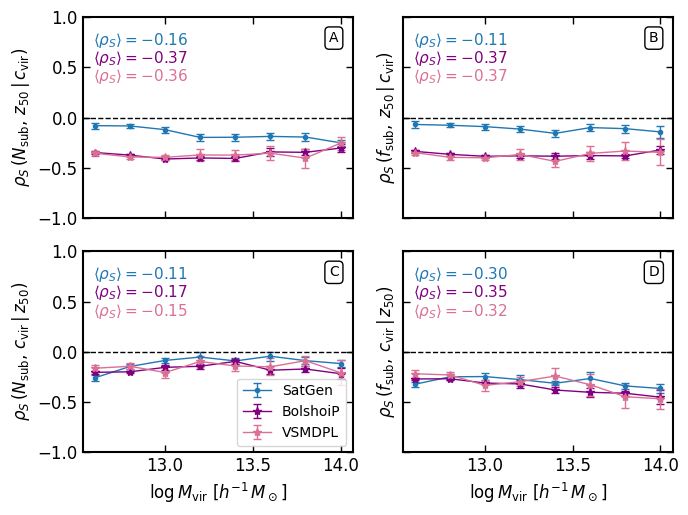

In [7]:
panels = [("A", "Nsub", "rho(X,z50|c)", r"$\rho_S\,(N_{\rm sub},\, z_{50}\,|\,c_{\rm vir})$"),
          ("B", "fsub", "rho(X,z50|c)", r"$\rho_S\,(f_{\rm sub},\, z_{50}\,|\,c_{\rm vir})$"),
          ("C", "Nsub", "rho(X,c|z50)", r"$\rho_S\,(N_{\rm sub},\, c_{\rm vir}\,|\,z_{50})$"),
          ("D", "fsub", "rho(X,c|z50)", r"$\rho_S\,(f_{\rm sub},\, c_{\rm vir}\,|\,z_{50})$")]

fig, axes = plt.subplots(2, 2, figsize=(double_textwidth, single_textwidth * 1.5), sharex=True, sharey=True)
for ax, (tag, x, key, ylabel) in zip(axes.flat, panels):
    for i, name in enumerate(data):
        t = results[(name, x)]
        ax.errorbar(t["logMvir"], t[key], yerr=t[key + "_err"], capsize=3, lw=1, **style[name])
        ax.text(0.04, 0.93 - 0.09 * i, rf"$\langle\rho_S\rangle = {t[key].mean():+.2f}$",
                color=style[name]["color"], transform=ax.transAxes, va="top", fontsize=11)
    ax.axhline(0, ls="--", color="k", lw=1)
    ax.text(0.93, 0.93, tag, transform=ax.transAxes, va="top", ha="center",
            bbox=dict(boxstyle="round", facecolor="white"))
    ax.set_ylabel(ylabel)
axes[0, 0].set_ylim(-1, 1)
axes[1, 0].legend(loc="lower right", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel(r"$\log M_{\rm vir}\ [h^{-1}\,M_\odot]$")
plt.tight_layout()
plt.show()

## 6. Figure: measured vs. "through-$z_{50}$" correlation with concentration

If abundance depended on concentration only through formation time, the measured correlation would equal the product

$$\rho_S^{\rm via\ z_{50}}(X|c_{\rm vir}) \;\equiv\; \rho_S(X|z_{50})\;\rho_S(z_{50}|c_{\rm vir}).$$

Solid lines show the measured $\rho_S(X|c_{\rm vir})$ (as in Figure 4, panels C and D); dashed lines show $\rho_S^{\rm via\ z_{50}}(X|c_{\rm vir})$. The vertical gap between the two is what the partial correlation in panels A and B of the previous figure quantifies.

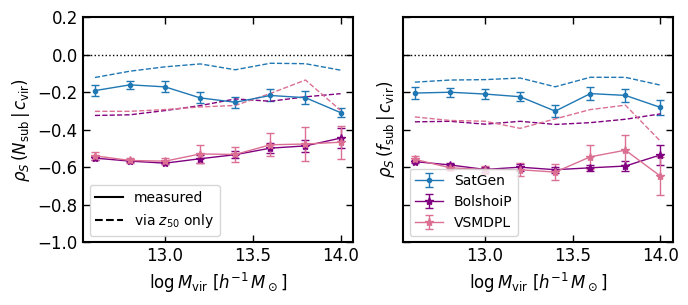

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(double_textwidth, single_textwidth * 0.9), sharex=True, sharey=True)
for ax, x, xlabel in zip(axes, ["Nsub", "fsub"], [r"N_{\rm sub}", r"f_{\rm sub}"]):
    for name in data:
        t = results[(name, x)]
        ax.errorbar(t["logMvir"], t["rho(X|c)"], yerr=t["rho(X|c)_err"], capsize=3, lw=1, **style[name])
        ax.plot(t["logMvir"], t["rho(X|z50)"] * t["rho(z50|c)"], ls="--", lw=1, color=style[name]["color"])
    ax.axhline(0, ls=":", color="k", lw=1)
    ax.set_ylabel(rf"$\rho_S\,({xlabel}\,|\,c_{{\rm vir}})$")
    ax.set_xlabel(r"$\log M_{\rm vir}\ [h^{-1}\,M_\odot]$")
axes[0].set_ylim(-1, 0.2)
axes[1].legend(loc="lower left", fontsize=10)
from matplotlib.lines import Line2D
axes[0].legend(handles=[Line2D([], [], color="k", ls="-", label="measured"),
                        Line2D([], [], color="k", ls="--", label=r"via $z_{50}$ only")],
               loc="lower left", fontsize=10)
plt.tight_layout()
plt.show()